# 06 — Deep learning: dense and LSTM autoencoders

**Goal**: test the deep learning approach most used for unsupervised anomaly detection on industrial sensors, autoencoders trained to reconstruct normal behaviour, under the same protocol as the other methods.

**Key findings**

- **Trained on the full training period, both autoencoders miss most failures**: the dense autoencoder detects 2/4 (1–2 across three seeds), the LSTM autoencoder 1/4. The unreported leak-like episodes of March taught them to reconstruct leaks.
- **Trained on the cleaned period** (without the four leak-like episodes the expert rule finds in training data), the **dense autoencoder detects 4/4 on all three seeds** with 0.69–0.83 false alarms per week, and the **LSTM autoencoder 4/4 in median** (2–4 across seeds) with 0.71 (0.42–0.78).
- The mechanism is visible in the reconstructions: without leaks in its training data, the LSTM cannot reproduce a flat, permanently loaded sequence and outputs a normal charge–discharge cycle instead, so failure scores are 16–27 times the test median. Trained with them, it reproduces the failure closely.
- **No early warning**: both autoencoders detect failure 4 around its reported start (median lead −0.5 and +0.1 h), where CUSUM on the motor current gives 12.9 h.
- **Cost**: 7–72 s of CPU training per model, seed variance, and an LSTM that had not converged after 100 epochs on the full data, for results that match but do not beat the rolling-baseline oil z-score of notebook 03 (0.28 false alarms per week).

In [1]:
import os
import time
import warnings
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir("..")
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from metrobench import deep
from metrobench import evaluation as ev
from metrobench.data import FAILURES, failure_mask, load, sustained_load_episodes
from metrobench.features import load_features
from metrobench.plotstyle import FAILURE, INK_MUTED, SERIES, use_style

use_style()
torch.set_num_threads(4)
FIG, RESULTS = Path("docs/figures"), Path("results")
grid, X = load_features()
X_train, _ = ev.split(X)
episodes = sustained_load_episodes(load())
unreported = episodes[~episodes.reported]
train_episodes = episodes[episodes.start < ev.SPLIT]
X_train_clean = X_train[~failure_mask(X_train.index, train_episodes)]
SEEDS = range(3)

## 1. Models

An autoencoder compresses its input through a narrow layer and reconstructs it. Trained on normal data only, it learns to reconstruct normal patterns; a pattern it has not learned is reconstructed poorly, and the reconstruction error is the anomaly score.

| Model | Input | Architecture |
|---|---|---|
| **Dense autoencoder** | the 18 window features of one minute | 18 → 12 → 6 → 12 → 18, ReLU |
| **LSTM autoencoder** | a 2-hour sequence (24 × 5-minute means) of 5 raw signals: motor current, load state, oil temperature, TP2, reservoir pressure | LSTM encoder (32 units) → last hidden state → LSTM decoder (32 units) → linear output |

Training: Adam (learning rate 10⁻³), mean squared error, inputs robust-scaled with training statistics. The last 10% of the training period is held out, and training stops when its loss has not improved for 5 epochs (at most 100). These settings are fixed in advance; early stopping only looks at training-period data.

Following notebook 05, each model is trained twice: on the **full** training period, and on a **cleaned** one without the four leak-like episodes that the expert rule finds in training data. Each configuration is run with 3 seeds.

In [2]:
runs, histories, scores, fits, timing = [], {}, {}, {}, {}
configs = [("Dense AE", "full"), ("Dense AE", "cleaned"), ("LSTM AE", "full"), ("LSTM AE", "cleaned")]
for model, data in configs:
    for seed in SEEDS:
        t0 = time.perf_counter()
        if model == "Dense AE":
            score, _, history = deep.dense_autoencoder(X, X_train if data == "full" else X_train_clean, seed=seed)
            fit = None
        else:
            score, history, fit = deep.lstm_autoencoder(grid, ev.SPLIT, exclude=None if data == "full" else train_episodes, seed=seed)
        timing.setdefault((model, data), []).append(time.perf_counter() - t0)
        row = ev.summarize({f"{model}, {data}": score}, unreported=unreported)
        runs.append(row.reset_index().assign(model=model, data=data, seed=seed, epochs=len(history)))
        if seed == 0:
            histories[(model, data)], scores[(model, data)], fits[(model, data)] = history, score, fit
runs = pd.concat(runs, ignore_index=True)
runs.to_csv(RESULTS / "06_deep_learning_runs.csv", index=False)

## 2. Training

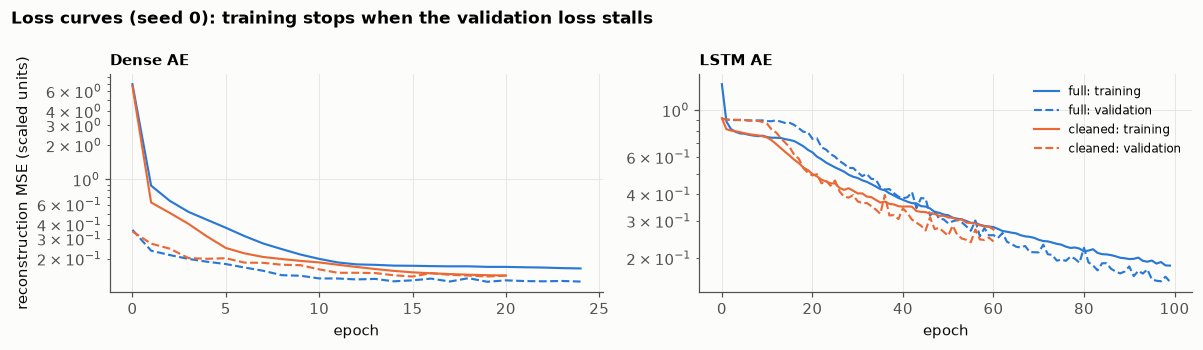

epochs (min)  epochs (max)
model    data                               
Dense AE full               25            54
         cleaned            19            29
LSTM AE  full              100           100
         cleaned            61            92

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
for ax, model in zip(axes, ["Dense AE", "LSTM AE"]):
    for k, data in enumerate(["full", "cleaned"]):
        h = np.array(histories[(model, data)])
        ax.plot(h[:, 0], color=SERIES[k], lw=1.4, label=f"{data}: training")
        ax.plot(h[:, 1], color=SERIES[k], lw=1.4, ls="--", label=f"{data}: validation")
    ax.set_title(model, fontsize=10)
    ax.set_xlabel("epoch")
    ax.set_yscale("log")
axes[0].set_ylabel("reconstruction MSE (scaled units)")
axes[1].legend(fontsize=8)
fig.suptitle("Loss curves (seed 0): training stops when the validation loss stalls", x=0.01, ha="left", fontsize=11, fontweight="bold")
fig.tight_layout()
fig.savefig(FIG / "06_training.png")
plt.show()
runs.groupby(["model", "data"], sort=False)["epochs"].agg(["min", "max"]).rename(columns=lambda c: f"epochs ({c})")

## 3. Results on the test period

In [4]:
def span(s, fmt="{:.2f}"):
    s = s.astype(float)
    lo, hi = s.min(), s.max()
    if np.isnan(lo):
        return "–"
    return fmt.format(s.median()) if lo == hi else f"{fmt.format(s.median())} ({fmt.format(lo)}–{fmt.format(hi)})"

summary = runs.groupby(["model", "data"], sort=False).agg(
    detected=("detected", lambda s: span(s, "{:.0f}")),
    lead_F4_h=("lead_h_4", lambda s: span(s, "{:.1f}")),
    false_alarms_per_week=("false_alarms_per_week", span),
    best_detected=("best_detected", lambda s: span(s, "{:.0f}")),
)
summary["train + score (s)"] = [round(np.median(timing[k]), 0) for k in summary.index]
summary

detected        lead_F4_h false_alarms_per_week  \
model    data                                                      
Dense AE full     2 (1–2)  6.2 (-0.3–12.6)      0.97 (0.69–1.04)   
         cleaned        4  -0.5 (-0.5–0.3)      0.83 (0.69–0.83)   
LSTM AE  full     1 (1–2)    1.7 (1.4–2.7)      1.48 (1.41–1.55)   
         cleaned  4 (2–4)   0.1 (-0.6–1.0)      0.71 (0.42–0.78)   

                 best_detected  train + score (s)  
model    data                                      
Dense AE full                0               11.0  
         cleaned             4                7.0  
LSTM AE  full                0               72.0  
         cleaned             4               60.0

In [5]:
numeric = runs.astype({"detected": float, "false_alarms_per_week": float, "lead_h_4": float})
medians = numeric.groupby(["model", "data"], sort=False)[["detected", "false_alarms_per_week", "lead_h_4"]].median()
medians.to_csv(RESULTS / "06_deep_learning.csv")
per_failure = numeric.groupby(["model", "data"], sort=False)[[f"lead_h_{i}" for i in FAILURES.index]].agg(lambda s: s.notna().sum())
per_failure.columns = [f"F{i} detected (of 3 seeds)" for i in FAILURES.index]
per_failure

F1 detected (of 3 seeds)  F2 detected (of 3 seeds)  \
model    data                                                          
Dense AE full                            0                         0   
         cleaned                         3                         3   
LSTM AE  full                            0                         0   
         cleaned                         2                         2   

                  F3 detected (of 3 seeds)  F4 detected (of 3 seeds)  
model    data                                                         
Dense AE full                            3                         2  
         cleaned                         3                         3  
LSTM AE  full                            1                         3  
         cleaned                         3                         3

The pattern of notebook 05 repeats. The training data decide the outcome more than the architecture: both autoencoders trained on the full period are nearly blind, both trained on the cleaned period detect all four failures (the LSTM on two of its three seeds). Once cleaned, the dense autoencoder on 18 hand-made features is as good as the LSTM on raw signals and more stable across seeds, at a tenth of the cost: learning features from raw sequences brings nothing here, because the window features already describe the cycle. Neither gives an early warning on failure 4, which only the accumulating charts (CUSUM) and the density-based LOF did.

## 4. Why cleaning matters: a model reconstructs what it has seen

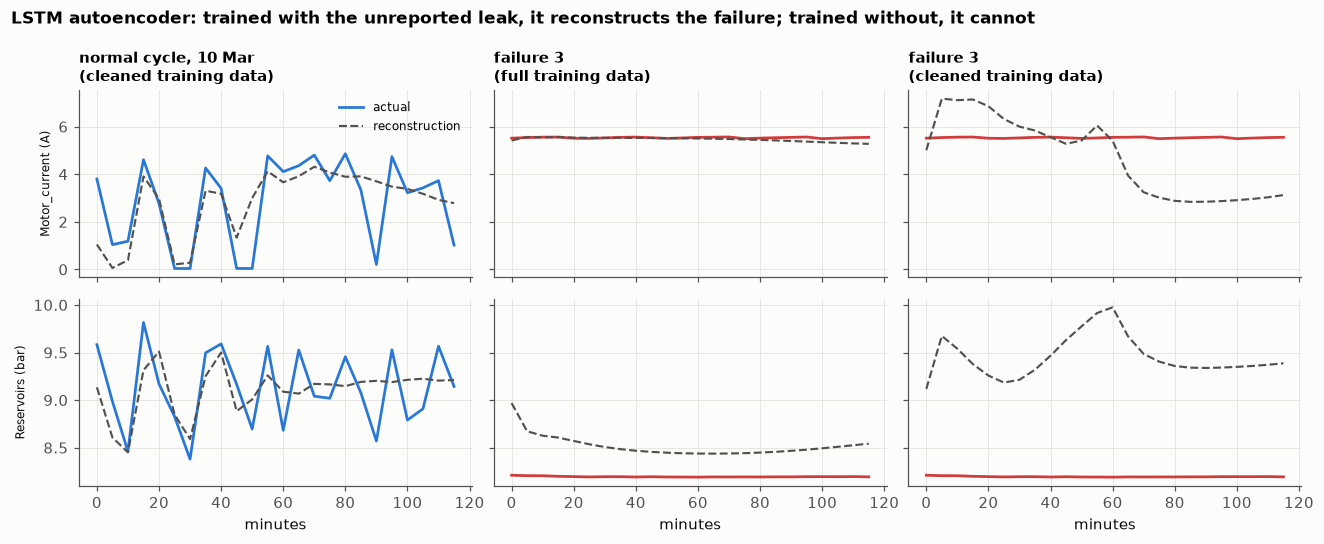

In [6]:
leak_end = FAILURES.loc[3, "start"] + pd.Timedelta("12h")
normal_end = pd.Timestamp("2020-03-10 12:00")
panels = [(fits[("LSTM AE", "cleaned")], normal_end, "normal cycle, 10 Mar\n(cleaned training data)", SERIES[0]),
          (fits[("LSTM AE", "full")], leak_end, "failure 3\n(full training data)", FAILURE),
          (fits[("LSTM AE", "cleaned")], leak_end, "failure 3\n(cleaned training data)", FAILURE)]
fig, axes = plt.subplots(2, 3, figsize=(12, 5), sharex=True, sharey="row")
for col, (fit, end, title, color) in enumerate(panels):
    actual, rebuilt = fit.reconstruct(grid, end)
    minutes = np.arange(len(actual)) * 5
    for row, signal, unit in [(0, "Motor_current", "A"), (1, "Reservoirs", "bar")]:
        ax = axes[row, col]
        ax.plot(minutes, actual[signal], color=color, lw=1.8, label="actual")
        ax.plot(minutes, rebuilt[signal], color=INK_MUTED, lw=1.4, ls="--", label="reconstruction")
        if col == 0:
            ax.set_ylabel(f"{signal} ({unit})", fontsize=8)
    axes[0, col].set_title(title, fontsize=10)
    axes[1, col].set_xlabel("minutes")
axes[0, 0].legend(fontsize=8)
fig.suptitle("LSTM autoencoder: trained with the unreported leak, it reconstructs the failure; trained without, it cannot",
             x=0.01, ha="left", fontsize=11, fontweight="bold")
fig.tight_layout()
fig.savefig(FIG / "06_reconstruction.png")
plt.show()

In [7]:
table = {}
for data in ["full", "cleaned"]:
    score = scores[("LSTM AE", data)]
    score_train, score_test = ev.split(score)
    during = {i: score.loc[s:e].median() for i, (s, e) in FAILURES[["start", "end"]].iterrows()}
    table[f"LSTM AE, {data}, seed 0"] = pd.Series(
        {"calibrated threshold": ev.calibrate(score_train), "median score, test period": score_test.median()}
        | {f"median score, failure {i}": v for i, v in during.items()})
pd.DataFrame(table).round(2)

,"LSTM AE, full, seed 0","LSTM AE, cleaned, seed 0"
calibrated threshold,2.11,4.54
"median score, test period",0.19,0.35
"median score, failure 1",0.03,5.60
"median score, failure 2",0.07,8.09
"median score, failure 3",0.34,9.16
"median score, failure 4",0.97,6.10


Left: the cleaned model reconstructs a normal cycle roughly, following the on/off pattern. Centre: the model trained on the full period has seen the March 29 leak; it reconstructs the flat current of failure 3 and part of its low reservoir pressure, so the error stays small. Right: the cleaned model has never seen a stopped cycle; it outputs a cycle-like shape and a reservoir pressure around 9.5 bar where the real one sits at 8.2 bar. An autoencoder flags what it cannot reproduce, and it can reproduce whatever its training data contained, including unreported faults.

## 5. Verdict

| | Best deep learning result | Best earlier result |
|---|---|---|
| Failures detected | 4/4 (dense AE, cleaned; all seeds) | 4/4 (several) |
| False alarms per week | 0.83 (0.69–0.83) | 0.28 (rolling-baseline oil z, notebook 03) |
| Early warning on failure 4 | none | 12.9 h (CUSUM, motor current) |
| Training cost | 7–72 s per model on CPU, 3 seeds | none to seconds |
| Requires | a curated training set | one feature |

Deep autoencoders work here only once the training data are cleaned, and then match the simpler methods without beating them. With one machine, four failures and a fault that shows as a sustained state, there is little for a deep model to learn that a well-chosen feature does not already capture. Notebook 07 puts all families side by side, with the uncertainty that four failures allow.